# Group Project Part 2: Discovering Patterns in SLCM Community Needs
**CS430 | Team: Niko Madden and AJ Rallo**

**Research question:** do SLCM intake records reveal distinct groups of need, and do those groups differ in housing pressure (rent arrears, eviction)? The written report summarises this notebook: its background, analysis, Questions 1-4, limitations and key takeaways follow the sections below.

This notebook uses K-Means and hierarchical (agglomerative) clustering to look for groups of SLCM intake cases with similar needs. Clusters are exploratory descriptions of the intake records, not judgments about families and not eligibility decisions.

**How to run:** put the five `SLCM_part2_*.csv` files in a `data/` folder next to this notebook and choose Restart & Run All. Keep `data/` private (do not push the CSVs to a public repository).

**Responsible use:** masked, classroom-approved data only. We do not try to identify anyone, we never display PIDs or ticket keys for individual families, and sensitive fields (age, gender, race/ethnicity, language, health identities) are used only to describe clusters, never to build them.

**Analysis switches (all sensitivity checks below reuse the same functions):**
- `UNIT`: `'person'` (default: one row per PID, the latest profile) or `'ticket'` (all 426 profile tickets).
- `DROP_DUPLICATES`: `False` by default (tickets staff marked Duplicate are kept and flagged, as in Part 1).
- `K_FINAL`: the number of clusters used for the final profiles (chosen in Task 2).

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.optimize import linear_sum_assignment

pd.set_option('display.width', 220, 'display.max_columns', 60, 'display.max_rows', 150, 'display.max_colwidth', 110)
sns.set_theme(style='whitegrid')

UNIT = 'person'
DROP_DUPLICATES = False
K_FINAL = 3
SEED = 42
DATA = 'data/'

## 2. Load the prepared files
`zip_code` is read as text so ZIPs are not turned into numbers.

In [2]:
profiles   = pd.read_csv(DATA + 'SLCM_part2_intake_profiles_clean.csv', dtype={'zip_code': str})
members    = pd.read_csv(DATA + 'SLCM_part2_household_members_clean.csv')
subs       = pd.read_csv(DATA + 'SLCM_part2_care_path_subtickets.csv')
dictionary = pd.read_csv(DATA + 'SLCM_part2_data_dictionary.csv')
provided_log = pd.read_csv(DATA + 'SLCM_part2_cleaning_log.csv')

print('Profiles:', profiles.shape, '| Members:', members.shape, '| Sub-tickets:', subs.shape)
print('Profiles + sub-tickets =', len(profiles) + len(subs), '(the original masked file had 639 rows, so nothing was dropped)')

Profiles: (426, 85) | Members: (993, 9) | Sub-tickets: (213, 10)
Profiles + sub-tickets = 639 (the original masked file had 639 rows, so nothing was dropped)


## 3. Read the data dictionary and cleaning log first
The `role` column says which columns are need indicators, context, data-quality flags, identifiers, or sensitive fields.

In [3]:
display(dictionary['role'].value_counts().to_frame('columns'))

,columns
role,
Need indicator - candidate feature,36
"Context - use to profile clusters, not as input",27
Data-quality flag,8
Identifier / structure - never a clustering input,7
"Sensitive - describe only, not a clustering input",7


In [4]:
display(provided_log[['step', 'field', 'rule', 'rows_affected']])

,step,field,rule,rows_affected
0,0,(file),"Loaded 639 rows x 93 cols (intake), 993 rows (members)",639
1,1,Issue Type,Profile tickets (New / Connected / Flourishing Neighbor Profile) -> profiles file; all other Issue Types -...,213
2,1,Parent key,Sub-tickets whose parent ticket is not in the export kept in sub-ticket file with parent_in_file = No,13
3,2,PID (sub-tickets),Added pid_matches_parent: sub-ticket PID differs from its parent profile's PID,31
4,3,Status,Status == 'Duplicate' flagged in is_duplicate_ticket (not removed),12
5,3,Created / Intake Date,Parsed 'dd/Mon/yy h:mm AM' text to ISO dates; added intake_month,426
6,3,PID,"Added pid_n_profile_tickets, pid_ticket_seq (1 = earliest), pid_is_latest_profile, pid_n_all_tickets (prof...",426
7,3,(sub-tickets),Counted linked care-path sub-tickets per profile: n_care_path_subtickets and sub_<group> counts,165
8,4,Zip Code,Kept first 5 digits of ZIP+4 values (e.g. 40214-5715 -> 40214),5
9,4,Zip Code,Non-numeric ZIP '402q1' set to missing,1


## Task 0: Revisit Part 1 and define the analysis unit

**Two Part 1 findings.**
1. *Only 426 of the 639 rows are real intakes.* The other 213 are care-path sub-tickets with no housing, income or household answers, so any statement about families must use the intake profiles. In Part 2 they are kept in their own file and used only to describe clusters.
2. *A job did not protect families from hardship.* Employed households had a median income of $2,000 against $0 for unemployed ones, yet eviction risk was 33% versus 25%, and risk did not fall as income rose. In Part 2 this means we should not treat income or employment alone as a stand-in for "need"; we cluster on several fields together and then check how housing pressure differs across the groups.

**One data-quality limitation.** 63 intakes (14.8%) have an Unknown eviction status, and in Part 1 they were counted as not at risk, which made 28.6% a floor. In Part 2 "Unknown" stays its own category in the features and in every table. We never read it as confirmed stability or confirmed risk. PID is also name-matched and approximate, so repeat-contact counts are lower or upper estimates, not exact.

**Observational unit: one person (PID), using their most recent profile ticket.**
- A person with three profile tickets would otherwise count three times and pull the clusters toward repeat callers. The unit we want to describe is a household reaching out to SLCM, not a ticket.
- The latest ticket describes the most recent situation. Earlier tickets are not deleted: they stay in the file, they feed the repeat-contact counts in Question 3, and a ticket-level run (all 426) is a sensitivity check in Task 2.
- Tickets staff marked Duplicate are kept and flagged (as in Part 1). A run without them is also a sensitivity check.
- Records with missing or "Unknown" answers are kept; how each field is handled is in the feature table in Task 1.

In [5]:
def make_analysis_table(profiles, unit='person', drop_duplicates=False):
    t = profiles.copy()
    if unit == 'person':
        t = t[t['pid_is_latest_profile'] == 'Yes']
    if drop_duplicates:
        t = t[t['is_duplicate_ticket'] == 'No']
    return t.reset_index(drop=True)

analysis = make_analysis_table(profiles, UNIT, DROP_DUPLICATES)

trail = pd.DataFrame([
    ('Rows in the original masked file', 639, 'profiles + sub-tickets'),
    ('Care-path sub-tickets (no intake answers)', len(subs), 'separate file; used only to describe clusters (Question 3)'),
    ('Profile tickets', len(profiles), 'required file'),
    ('Distinct people (PIDs) among the profile tickets', profiles['pid'].nunique(), 'approximate, name-matched'),
    ('Earlier tickets of repeat people (set aside, not deleted)', len(profiles) - profiles['pid'].nunique(), 'still used for repeat-contact counts'),
    ('Rows in the clustering table (one per person)', len(analysis), 'latest profile per PID'),
], columns=['step', 'rows', 'note'])
display(trail)

n_dup = int((analysis['is_duplicate_ticket'] == 'Yes').sum())
n_unknown = int((analysis['eviction_status'] == 'Unknown').sum())
print(f'Tickets flagged Duplicate inside the clustering table: {n_dup} (kept; a run without them is a sensitivity check)')
print(f'Eviction status Unknown: {n_unknown} of {len(analysis)} ({n_unknown/len(analysis):.1%}) (kept as its own category)')
print('People with 2+ profile tickets:', int((analysis['pid_n_profile_tickets'] >= 2).sum()),
      '| distribution of profile tickets per person:', analysis['pid_n_profile_tickets'].value_counts().sort_index().to_dict())

,step,rows,note
0,Rows in the original masked file,639,profiles + sub-tickets
1,Care-path sub-tickets (no intake answers),213,separate file; used only to describe clusters (Question 11)
2,Profile tickets,426,required file
3,Distinct people (PIDs) among the profile tickets,395,"approximate, name-matched"
4,"Earlier tickets of repeat people (set aside, not deleted)",31,still used for repeat-contact counts
5,Rows in the clustering table (one per person),395,latest profile per PID


Tickets flagged Duplicate inside the clustering table: 10 (kept; a run without them is a sensitivity check)
Eviction status Unknown: 56 of 395 (14.2%) (kept as its own category)
People with 2+ profile tickets: 27 | distribution of profile tickets per person: {1: 368, 2: 24, 3: 2, 4: 1}


## Task 1: Prepare features for unsupervised learning

**Feature choices.** We use fields marked *Need indicator* in the data dictionary that describe housing, income/employment and household composition, and that are filled in for (almost) every profile:

- **Housing:** `housing_group` (6 levels), `eviction_status` (Unknown kept as its own level), `section8_or_voucher`.
- **Income and employment:** `income_monthly` (log-transformed), `employment_status`, and the six `inc_src_*` income-source indicators.
- **Household:** `household_size_from_members` (additional members + 1, as in Part 1) and `children_17_under`.

**Deliberately left out of the clustering inputs (used later to describe clusters):**
- `past_due_rent`, `monthly_rent`, `rent_to_income_pct`: they come from a separate rent form that only 38-40% of profiles completed. Filling in 60% of a column would mean the clusters mostly reflect our imputation. They are the main profiling variables instead (Question 2).
- `utility_past_due`: 43% are "Not recorded" because the form has no "none" option, so the clusters would split on how the form was filled out.
- `has_court_date`: it is only recorded for eviction cases and repeats `eviction_status`.
- `zip_code`: 38 ZIPs (most with a handful of families) would fill the feature space with sparse columns and ZIP describes where a family lives, not what it needs. ZIP is used for profiling.
- Identifiers (`issue_key`, `pid`), data-quality flags, staff/workflow fields, and `high_arrears_3000` (an Assignment 3 label).
- Sensitive fields (age, gender, race/ethnicity, language, health identities): description only.

In [6]:
NUM = ['log_income', 'household_size_from_members', 'children_17_under']
CAT = ['housing_group', 'eviction_status', 'employment_status', 'section8_or_voucher']
BIN = ['inc_src_snap_tanf', 'inc_src_fulltime', 'inc_src_parttime',
       'inc_src_ssi_ssdi', 'inc_src_no_income', 'inc_src_other']

def add_features(t):
    t = t.copy()
    t['log_income'] = np.log1p(t['income_monthly'])
    return t

analysis = add_features(analysis)

Income: 31.6% are $0 (zero is a real answer here, not missing); median $925; max $9,000
Skew of income: 1.48 raw -> -0.67 after log(1 + income)
Income values converted from annual to monthly in the provided cleaning: 6 in this table
children_17_under: range 0-6, median 2; value 6+ (top-coded "More than 5" for children): 15
household_size_from_members: range 1-9, median 3; value 6+ (top-coded "More than 5" for children): 37


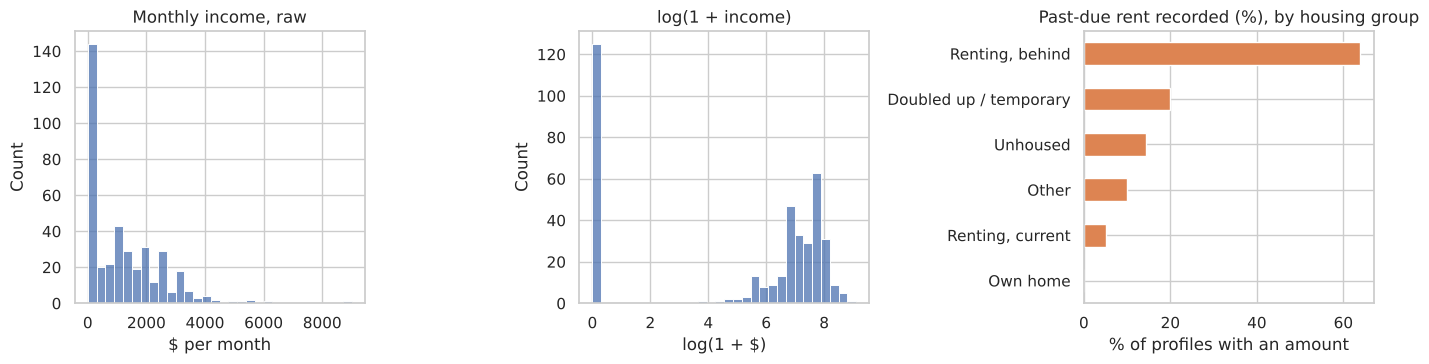

Past-due rent is recorded for 38.7% of the clustering table


In [7]:
inc = analysis['income_monthly']
print(f'Income: {(inc == 0).mean():.1%} are $0 (zero is a real answer here, not missing); median ${inc.median():,.0f}; max ${inc.max():,.0f}')
print(f'Skew of income: {inc.skew():.2f} raw -> {analysis["log_income"].skew():.2f} after log(1 + income)')
print('Income values converted from annual to monthly in the provided cleaning:', int((analysis['money_flag'].fillna('').str.contains('annual')).sum()), 'in this table')
for c in ['children_17_under', 'household_size_from_members']:
    print(f'{c}: range {analysis[c].min()}-{analysis[c].max()}, median {analysis[c].median():.0f}; value 6+ (top-coded "More than 5" for children): {(analysis[c] >= 6).sum()}')

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
sns.histplot(inc, bins=30, ax=ax[0], color='#4c72b0'); ax[0].set(title='Monthly income, raw', xlabel='$ per month')
sns.histplot(analysis['log_income'], bins=30, ax=ax[1], color='#4c72b0'); ax[1].set(title='log(1 + income)', xlabel='log(1 + $)')
known = analysis.groupby('housing_group')['past_due_rent'].apply(lambda s: s.notna().mean()).sort_values()
known.mul(100).plot(kind='barh', ax=ax[2], color='#dd8452'); ax[2].set(title='Past-due rent recorded (%), by housing group', xlabel='% of profiles with an amount', ylabel='')
plt.tight_layout(); plt.savefig('part2_fig_inputs.png', dpi=150); plt.show()
print(f'Past-due rent is recorded for {analysis["past_due_rent"].notna().mean():.1%} of the clustering table')

In [8]:
def pct_missing(col):
    return round(100 * analysis[col].isna().mean(), 1)

feature_table = pd.DataFrame([
    ('income_monthly -> log_income', 'Monthly household income ($)', pct_missing('income_monthly'), 'log(1 + x), then standardize', 'Core income measure; log handles the skew and the $0 values'),
    ('household_size_from_members', 'Additional members + 1 (primary contact)', pct_missing('household_size_from_members'), 'standardize', 'Household composition (the Part 1 definition)'),
    ('children_17_under', 'Children 17 and under (6 = "More than 5")', pct_missing('children_17_under'), 'standardize; 6 kept as a lower bound', 'Family stage; separates families with many children'),
    ('housing_group', 'Housing situation at intake (6 levels)', pct_missing('housing_group'), 'one-hot', 'Core housing measure; small categories already combined in the provided cleaning'),
    ('eviction_status', 'Currently being evicted / Not being evicted / Unknown', pct_missing('eviction_status'), 'one-hot; Unknown is its own level', 'Housing urgency; Unknown must not be read as "not at risk"'),
    ('employment_status', 'Employment situation (5 levels)', pct_missing('employment_status'), 'one-hot', 'Core employment measure'),
    ('section8_or_voucher', 'Has a Section 8 / housing voucher', pct_missing('section8_or_voucher'), 'one-hot', 'Housing subsidy changes how rent pressure shows up'),
    ('inc_src_* (6 flags)', 'SNAP/TANF, full-time, part-time, SSI/SSDI, no income, other', pct_missing('inc_src_snap_tanf'), '0/1; missing filled with most frequent value (0)', 'A household can have several sources; shows how income is made up'),
], columns=['field', 'what it represents', '% missing', 'preparation', 'why included'])
display(feature_table)
feature_table.to_csv('part2_feature_table.csv', index=False)

,field,what it represents,% missing,preparation,why included
0,income_monthly -> log_income,Monthly household income ($),0.0,"log(1 + x), then standardize",Core income measure; log handles the skew and the $0 values
1,household_size_from_members,Additional members + 1 (primary contact),0.0,standardize,Household composition (the Part 1 definition)
2,children_17_under,"Children 17 and under (6 = ""More than 5"")",0.0,standardize; 6 kept as a lower bound,Family stage; separates families with many children
3,housing_group,Housing situation at intake (6 levels),0.0,one-hot,Core housing measure; small categories already combined in the provided cleaning
4,eviction_status,Currently being evicted / Not being evicted / Unknown,0.0,one-hot; Unknown is its own level,"Housing urgency; Unknown must not be read as ""not at risk"""
5,employment_status,Employment situation (5 levels),0.0,one-hot,Core employment measure
6,section8_or_voucher,Has a Section 8 / housing voucher,0.0,one-hot,Housing subsidy changes how rent pressure shows up
7,inc_src_* (6 flags),"SNAP/TANF, full-time, part-time, SSI/SSDI, no income, other",1.0,0/1; missing filled with most frequent value (0),A household can have several sources; shows how income is made up


In [9]:
def make_preprocessor(num=NUM, cat=CAT, bin_=BIN):
    parts = []
    if num:  parts.append(('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), num))
    if cat:  parts.append(('cat', make_pipeline(SimpleImputer(strategy='constant', fill_value='Not recorded'),
                                               OneHotEncoder(handle_unknown='ignore', sparse_output=False)), cat))
    if bin_: parts.append(('bin', SimpleImputer(strategy='most_frequent'), bin_))
    return ColumnTransformer(parts)

pre = make_preprocessor()
X = pre.fit_transform(analysis)
feature_names = [n.split('__', 1)[1] for n in pre.get_feature_names_out()]
print('Clustering matrix:', X.shape, '(people x encoded features)')
print('Remaining missing values after preprocessing:', int(np.isnan(X).sum()))
print('Missing values filled: household_repairs_required is not used; inc_src_* missing =', int(analysis['inc_src_snap_tanf'].isna().sum()), 'people')

Clustering matrix: (395, 25) (people x encoded features)
Remaining missing values after preprocessing: 0
Missing values filled: household_repairs_required is not used; inc_src_* missing = 4 people


In [10]:
team_steps = pd.DataFrame([
    ('T0', 'Analysis unit', 'One row per PID: keep the latest profile ticket (pid_is_latest_profile == Yes)', len(profiles) - profiles['pid'].nunique(), 'Earlier tickets set aside, not deleted; they still feed the repeat-contact counts. Avoids counting one household several times'),
    ('T0', 'is_duplicate_ticket', 'Tickets marked Duplicate are kept and flagged; run without them as a sensitivity check', n_dup, 'Staff label is not verified; dropping them would silently change the counts'),
    ('T1', 'eviction_status', 'Unknown kept as its own category', n_unknown, 'Unknown is not confirmed stability or confirmed risk'),
    ('T1', 'income_monthly', 'log(1 + income); $0 kept as $0', int((inc == 0).sum()), 'Right-skewed, many true zeros; zero is not missing'),
    ('T1', 'children_17_under', 'Value 6 (top-coded "More than 5") kept as 6', int((analysis['children_17_under'] >= 6).sum()), 'Lower bound; treated as 6 for distances'),
    ('T1', 'inc_src_* flags', 'Missing flags filled with the most frequent value', int(analysis['inc_src_snap_tanf'].isna().sum()), 'Only a few people; avoids dropping them'),
    ('T1', 'past_due_rent, monthly_rent, rent_to_income_pct', 'Not used as clustering inputs; used for profiling only', int(analysis['past_due_rent'].isna().sum()), 'Separate rent form; missing for most profiles (blank is not $0)'),
    ('T1', 'utility_past_due', 'Not used as a clustering input; used for profiling only', int((analysis['utility_past_due'] == 'Not recorded').sum()), '"Not recorded" cannot be read as "No"'),
    ('T1', 'zip_code', 'Not used as a clustering input; used for profiling only', int(analysis['zip_code'].nunique()), 'Many sparse ZIPs; location is not a need'),
], columns=['step', 'field', 'rule', 'rows_affected', 'reason'])
full_log = pd.concat([provided_log.assign(source='provided'), team_steps.assign(source='team')], ignore_index=True)
full_log.to_csv('part2_cleaning_log_extended.csv', index=False)
display(team_steps)

,step,field,rule,rows_affected,reason
0,T0,Analysis unit,One row per PID: keep the latest profile ticket (pid_is_latest_profile == Yes),31,"Earlier tickets set aside, not deleted; they still feed the repeat-contact counts. Avoids counting one hou..."
1,T0,is_duplicate_ticket,Tickets marked Duplicate are kept and flagged; run without them as a sensitivity check,10,Staff label is not verified; dropping them would silently change the counts
2,T1,eviction_status,Unknown kept as its own category,56,Unknown is not confirmed stability or confirmed risk
3,T1,income_monthly,log(1 + income); $0 kept as $0,125,"Right-skewed, many true zeros; zero is not missing"
4,T1,children_17_under,"Value 6 (top-coded ""More than 5"") kept as 6",15,Lower bound; treated as 6 for distances
5,T1,inc_src_* flags,Missing flags filled with the most frequent value,4,Only a few people; avoids dropping them
6,T1,"past_due_rent, monthly_rent, rent_to_income_pct",Not used as clustering inputs; used for profiling only,242,Separate rent form; missing for most profiles (blank is not $0)
7,T1,utility_past_due,Not used as a clustering input; used for profiling only,168,"""Not recorded"" cannot be read as ""No"""
8,T1,zip_code,Not used as a clustering input; used for profiling only,32,Many sparse ZIPs; location is not a need


## Task 2: Find and compare household-need patterns

### 2.1 K-Means: how many clusters?
We try k = 2 to 8 and look at the elbow plot (inertia), the average silhouette score (-1 to 1; values near 0 mean clusters overlap), and seed stability (do different random starts give the same groups?).

,inertia,kmeans_silhouette,ward_silhouette,smallest_cluster,seed_stability_ARI
k,,,,,
2,1953.860,0.208,0.208,128,0.746
3,1636.448,0.211,0.213,67,0.807
4,1514.362,0.171,0.147,33,0.622
5,1427.168,0.151,0.145,28,0.640
6,1349.913,0.135,0.136,18,0.574
7,1290.389,0.136,0.133,22,0.553
8,1248.433,0.121,0.103,20,0.500


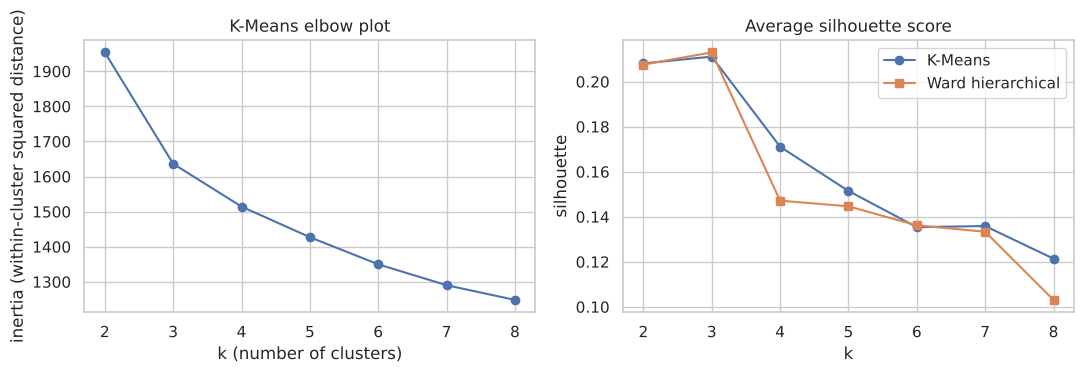

In [11]:
ks = range(2, 9)
scan = []
for k in ks:
    km_k = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X)
    ag_k = AgglomerativeClustering(n_clusters=k, linkage='ward').fit(X)
    seed_ari = np.mean([adjusted_rand_score(km_k.labels_, KMeans(n_clusters=k, n_init=1, random_state=s).fit(X).labels_) for s in range(20)])
    scan.append(dict(k=k, inertia=km_k.inertia_, kmeans_silhouette=silhouette_score(X, km_k.labels_),
                     ward_silhouette=silhouette_score(X, ag_k.labels_), smallest_cluster=int(np.bincount(km_k.labels_).min()),
                     seed_stability_ARI=seed_ari))
scan = pd.DataFrame(scan).set_index('k')
display(scan.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(scan.index, scan['inertia'], marker='o', color='#4c72b0'); ax[0].set(title='K-Means elbow plot', xlabel='k (number of clusters)', ylabel='inertia (within-cluster squared distance)')
ax[1].plot(scan.index, scan['kmeans_silhouette'], marker='o', label='K-Means', color='#4c72b0')
ax[1].plot(scan.index, scan['ward_silhouette'], marker='s', label='Ward hierarchical', color='#dd8452')
ax[1].set(title='Average silhouette score', xlabel='k', ylabel='silhouette'); ax[1].legend()
plt.tight_layout(); plt.savefig('part2_fig_k_choice.png', dpi=150); plt.show()


**Choosing k.** The silhouette scores are low for every k: the best are 0.208 (k = 2) and 0.211 (k = 3), and the score falls to 0.171 at k = 4. Intake records overlap a lot, so the clusters are soft, descriptive patterns, not sharply separated groups. The elbow plot has no sharp bend, only a gradual flattening.

We use **k = 3**, for three reasons.
1. It has the highest silhouette score for both K-Means (0.211) and Ward (0.213), essentially tied with k = 2.
2. It is much more repeatable. Different random starts give nearly the same groups at k = 3 (seed-stability ARI 0.81) but not at k = 4 (0.62).
3. It adds something over k = 2. The k = 2 solution separates the 128 people with no reported income from the other 267; k = 3 also pulls out 66 households with many people.

The k = 4 solution is *not* a reliable pattern. As the table above shows, its inertia is almost identical across seeds, but the four group sizes keep changing (for example 33/97/114/151 versus 34/111/119/131): the extra cluster is just an arbitrary cut through the large middle group. All three k = 3 clusters have at least 66 people.


In [12]:
km = KMeans(n_clusters=K_FINAL, n_init=50, random_state=SEED).fit(X)
km2 = KMeans(n_clusters=2, n_init=50, random_state=SEED).fit(X)
print(f'K-Means k={K_FINAL}: cluster sizes', np.bincount(km.labels_).tolist(), '| silhouette', round(silhouette_score(X, km.labels_), 3))
print('How the k = 2 groups split into the k = 3 groups (rows = k = 2, columns = k = 3):'); display(pd.crosstab(km2.labels_, km.labels_))

rows = []
for s in range(12):
    k4 = KMeans(n_clusters=4, n_init=50, random_state=s).fit(X)
    rows.append(dict(seed=s, inertia=round(k4.inertia_, 1), sizes=sorted(np.bincount(k4.labels_).tolist())))
display(pd.DataFrame(rows).set_index('seed'))

def name_clusters(df, labels):
    prof = df.assign(c=labels).groupby('c').agg(hh=('household_size_from_members', 'mean'),
                                               zero=('income_monthly', lambda s: (s == 0).mean()),
                                               inc=('income_monthly', 'median'))
    names = {prof['hh'].idxmax(): 'Largest households'}
    rest = prof.drop(index=list(names))
    zero_cluster = rest['zero'].idxmax()
    names[zero_cluster] = 'No reported income'
    names[rest.drop(index=[zero_cluster]).index[0]] = 'Some income, smaller households'
    return names

NAMES = name_clusters(analysis, km.labels_)
ORDER = ['No reported income', 'Some income, smaller households', 'Largest households']
analysis['kmeans'] = pd.Categorical(pd.Series(km.labels_).map(NAMES), categories=ORDER, ordered=True)
print('Cluster names:', {int(k): v for k, v in NAMES.items()})

K-Means k=3: cluster sizes [66, 208, 121] | silhouette 0.212
How the k = 2 groups split into the k = 3 groups (rows = k = 2, columns = k = 3):


col_0,0,1,2
row_0,,,
0,8,1,119
1,58,207,2


,inertia,sizes
seed,,
0,1514.4,"[33, 97, 114, 151]"
1,1514.5,"[34, 114, 120, 127]"
2,1514.4,"[34, 111, 119, 131]"
3,1514.4,"[34, 112, 119, 130]"
4,1514.4,"[33, 97, 114, 151]"
5,1514.4,"[33, 97, 114, 151]"
6,1514.9,"[32, 87, 113, 163]"
7,1514.4,"[34, 112, 119, 130]"
8,1514.7,"[32, 114, 121, 128]"


Cluster names: {0: 'Largest households', 2: 'No reported income', 1: 'Some income, smaller households'}


### 2.2 Hierarchical (agglomerative) clustering
Ward linkage on the same prepared matrix. The dendrogram shows how clusters merge; the horizontal line marks the cut that gives the final number of clusters.

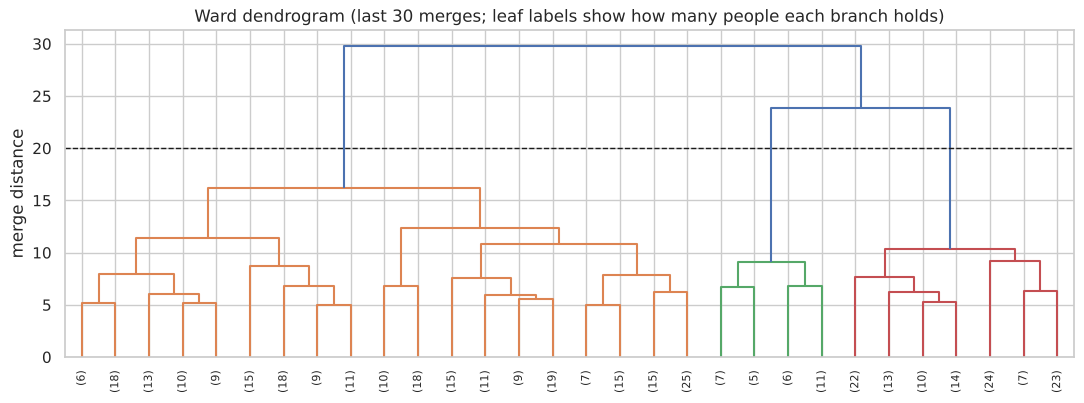

,silhouette,cluster_sizes
linkage,,
ward,0.213,"[253, 113, 29]"
average,0.178,"[346, 2, 47]"
complete,0.091,"[283, 83, 29]"


In [13]:
Z = linkage(X, method='ward')
cut_height = (Z[-K_FINAL + 1, 2] + Z[-K_FINAL, 2]) / 2
fig, ax = plt.subplots(figsize=(11, 4.2))
dendrogram(Z, truncate_mode='lastp', p=30, show_leaf_counts=True, leaf_rotation=90, leaf_font_size=8, color_threshold=cut_height, ax=ax)
ax.axhline(cut_height, ls='--', c='k', lw=1); ax.set(title='Ward dendrogram (last 30 merges; leaf labels show how many people each branch holds)', ylabel='merge distance')
plt.tight_layout(); plt.savefig('part2_fig_dendrogram.png', dpi=150); plt.show()

rows = []
for link in ['ward', 'average', 'complete']:
    lab = AgglomerativeClustering(n_clusters=K_FINAL, linkage=link).fit_predict(X)
    rows.append(dict(linkage=link, silhouette=silhouette_score(X, lab), cluster_sizes=np.bincount(lab).tolist()))
display(pd.DataFrame(rows).set_index('linkage').round(3))

In [14]:
ag = AgglomerativeClustering(n_clusters=K_FINAL, linkage='ward').fit(X)
overlap = pd.crosstab(ag.labels_, km.labels_).to_numpy()
rows_i, cols_j = linear_sum_assignment(-overlap)
match = dict(zip(rows_i, cols_j))
analysis['hierarchical'] = pd.Categorical(pd.Series(ag.labels_).map(lambda c: NAMES[match[c]]), categories=ORDER, ordered=True)

ari = adjusted_rand_score(km.labels_, ag.labels_)
agree = (analysis['kmeans'] == analysis['hierarchical']).mean()
print(f'Agreement between methods: adjusted Rand index = {ari:.2f}; {agree:.1%} of people land in the matched cluster')
print('Rows = K-Means cluster, columns = hierarchical cluster (matched by overlap):')
display(pd.crosstab(analysis['kmeans'], analysis['hierarchical'], margins=True))
print('Share of each K-Means cluster found in the matching hierarchical cluster:')
display((pd.crosstab(analysis['kmeans'], analysis['hierarchical'], normalize='index') * 100).round(0))

Agreement between methods: adjusted Rand index = 0.70; 87.1% of people land in the matched cluster
Rows = K-Means cluster, columns = hierarchical cluster (matched by overlap):


hierarchical,No reported income,"Some income, smaller households",Largest households,All
kmeans,,,,
No reported income,112,4,5,121
"Some income, smaller households",0,208,0,208
Largest households,1,41,24,66
All,113,253,29,395


Share of each K-Means cluster found in the matching hierarchical cluster:


hierarchical,No reported income,"Some income, smaller households",Largest households
kmeans,,,
No reported income,93.0,3.0,4.0
"Some income, smaller households",0.0,100.0,0.0
Largest households,2.0,62.0,36.0


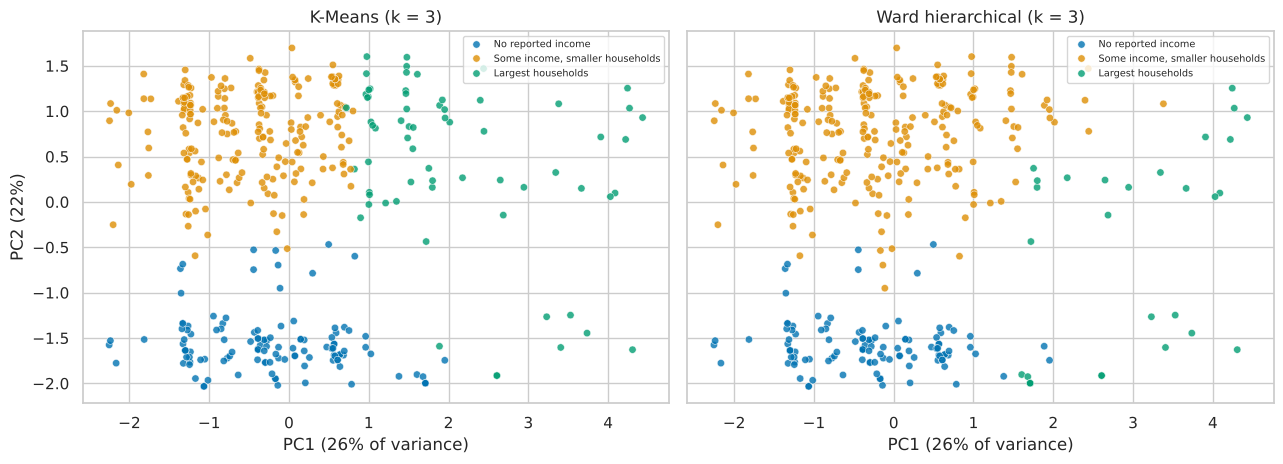

In [15]:
pca = PCA(n_components=2, random_state=SEED).fit(X)
P = pca.transform(X)
pal = dict(zip(ORDER, sns.color_palette('colorblind', len(ORDER))))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), sharex=True, sharey=True)
for a, col, title in zip(ax, ['kmeans', 'hierarchical'], [f'K-Means (k = {K_FINAL})', f'Ward hierarchical (k = {K_FINAL})']):
    sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=analysis[col].astype(str), hue_order=ORDER, palette=pal, s=28, alpha=.8, ax=a)
    a.set(title=title, xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)', ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.0%})')
    a.legend(fontsize=7, title='')
plt.tight_layout(); plt.savefig('part2_fig_pca.png', dpi=150); plt.show()


**Comparing the methods.** The adjusted Rand index is 0.70 and 87.1% of people land in the matched cluster, so the two methods agree on the broad picture.
- *No reported income:* 93% of the K-Means cluster (112 of 121) is in the matching Ward cluster.
- *Some income, smaller households:* all 208 K-Means members are in the matching Ward cluster (Ward's version is larger, 253, because it also absorbs people from the third group).
- *Largest households:* the methods disagree. Only 24 of the 66 K-Means members (36%) land in the matching Ward cluster; Ward sends 41 of them into the middle group and keeps a smaller, more extreme group of 29 (mean household size 6.9 versus 5.9). Household size runs along a continuum, so where to cut it is a judgment call, not a fact in the data.

Other linkages did worse (average linkage makes a 346-person cluster; complete linkage has silhouette 0.09), so we use Ward.


### 2.3 How stable are the clusters?
Three checks: (1) refit K-Means on 200 bootstrap resamples and compare with the main labels; (2) change the analysis unit or drop the duplicate-flagged tickets; (3) drop input groups. Every variant is refit with the same k as the final model. The adjusted Rand index (ARI) is 1 for identical groupings and 0 for random agreement.

In [16]:
def bootstrap_ari(X, k, reference, n_boot=200):
    rng = np.random.default_rng(SEED); out = []
    for b in range(n_boot):
        idx = rng.integers(0, len(X), len(X))
        lab = KMeans(n_clusters=k, n_init=10, random_state=b).fit(X[idx]).predict(X)
        out.append(adjusted_rand_score(reference, lab))
    return np.array(out)

boot_rows = []
for k in sorted({2, K_FINAL, 4}):
    ref = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(X).labels_
    a = bootstrap_ari(X, k, ref)
    boot_rows.append(dict(k=k, mean_ARI=a.mean(), pct5=np.percentile(a, 5), pct95=np.percentile(a, 95)))
display(pd.DataFrame(boot_rows).set_index('k').round(2))

,mean_ARI,pct5,pct95
k,,,
2,0.88,-0.03,1.00
3,0.86,0.76,0.97
4,0.71,0.49,0.92


In [17]:
def kmeans_variant(table, num=NUM, cat=CAT, bin_=BIN, k=K_FINAL):
    t = add_features(table)
    Xv = make_preprocessor(num, cat, bin_).fit_transform(t)
    return pd.Series(KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(Xv).labels_, index=t['issue_key'].to_numpy())

main_labels = pd.Series(km.labels_, index=analysis['issue_key'].to_numpy())
variants = {
    'ticket level (all 426 profile tickets)':   kmeans_variant(make_analysis_table(profiles, 'ticket')),
    'person level, duplicate-flagged removed':   kmeans_variant(make_analysis_table(profiles, 'person', True)),
    'without the income-source flags':           kmeans_variant(analysis, bin_=[]),
    'without Section 8 / voucher':               kmeans_variant(analysis, cat=['housing_group', 'eviction_status', 'employment_status']),
    'without household size (kids kept)':        kmeans_variant(analysis, num=['log_income', 'children_17_under']),
}
rows = []
for name, lab in variants.items():
    common = main_labels.index.intersection(lab.index)
    rows.append(dict(variant=name, people_compared=len(common), ARI_vs_main=adjusted_rand_score(main_labels[common], lab[common])))
display(pd.DataFrame(rows).set_index('variant').round(2))

,people_compared,ARI_vs_main
variant,,
ticket level (all 426 profile tickets),395,0.80
"person level, duplicate-flagged removed",385,0.98
without the income-source flags,395,0.95
without Section 8 / voucher,395,0.97
without household size (kids kept),395,0.65



**Reading the stability checks.**
- *Bootstrap:* for k = 3 the clusters come back with mean ARI 0.86 (5th to 95th percentile 0.76 to 0.97), better than k = 4 (0.71). For k = 2 the average is similar (0.88) but some resamples found a completely different split (5th percentile about 0), so the k = 2 split is less dependable than it first looks.
- *Unit and duplicates:* running at ticket level (all 426 tickets) gives ARI 0.80, and removing duplicate-flagged tickets gives 0.98. Both support using one row per person, and the duplicates make almost no difference.
- *Inputs:* dropping the income-source flags (0.95) or Section 8 (0.97) changes little. Dropping household size changes the grouping most (0.65), which tells us household size is what creates the third cluster.

The clusters are descriptions of this particular set of features, not a fixed truth about SLCM families, and people near a boundary move between groups.


### 2.4 Profile the final clusters
Tables first (sizes, numeric summaries, category shares), then plots. The columns in these first tables are the clustering inputs, so differences between clusters are expected by construction. Variables that were **not** inputs (rent arrears, utilities, court dates, ZIP, repeat contact) are in the policy-question sections. (The written report calls the first cluster "0 income"; here it is "No reported income".)

In [18]:
g = analysis.groupby('kmeans', observed=True)
summary = pd.DataFrame({
    'people': g.size(),
    '% of people': (g.size() / len(analysis) * 100).round(1),
    'median monthly income ($)': g['income_monthly'].median(),
    '% with $0 income': (g['income_monthly'].apply(lambda s: (s == 0).mean()) * 100).round(0),
    'mean household size': g['household_size_from_members'].mean().round(1),
    'mean children 17 and under': g['children_17_under'].mean().round(1),
    'mean members aged 0-5 (roster)': g['members_n_age_0_5'].mean().round(1),
})
display(summary)

,people,% of people,median monthly income ($),% with $0 income,mean household size,mean children 17 and under,mean members aged 0-5 (roster)
kmeans,,,,,,,
No reported income,121,30.6,0.0,97.0,3.1,2.1,1.0
"Some income, smaller households",208,52.7,1500.0,0.0,2.7,1.8,0.8
Largest households,66,16.7,1200.0,12.0,5.9,4.2,1.9


In [19]:
def share_table(col):
    return (pd.crosstab(analysis['kmeans'], analysis[col], normalize='index') * 100).round(0)

for col in ['housing_group', 'employment_status', 'eviction_status', 'section8_or_voucher']:
    print(col); display(share_table(col))
src = analysis.groupby('kmeans', observed=True)[BIN].mean().mul(100).round(0)
src.columns = [c.replace('inc_src_', '') for c in src.columns]
print('Income sources reported (% of cluster; people can report several)'); display(src)

housing_group


housing_group,Doubled up / temporary,Other,Own home,"Renting, behind","Renting, current",Unhoused
kmeans,,,,,,
No reported income,12.0,2.0,0.0,48.0,35.0,3.0
"Some income, smaller households",7.0,2.0,3.0,58.0,28.0,2.0
Largest households,3.0,5.0,3.0,58.0,24.0,8.0


employment_status


employment_status,Employed,"Employed, but need more hours and/or different work",Other,Unemployed and not looking for work,Unemployed but want to find work
kmeans,,,,,
No reported income,5.0,2.0,4.0,7.0,83.0
"Some income, smaller households",40.0,21.0,8.0,7.0,24.0
Largest households,32.0,12.0,9.0,5.0,42.0


eviction_status


eviction_status,Currently being evicted,Not being evicted,Unknown
kmeans,,,
No reported income,20.0,68.0,12.0
"Some income, smaller households",28.0,58.0,14.0
Largest households,30.0,53.0,17.0


section8_or_voucher


section8_or_voucher,No,Yes
kmeans,,
No reported income,70.0,30.0
"Some income, smaller households",86.0,14.0
Largest households,71.0,29.0


Income sources reported (% of cluster; people can report several)


,snap_tanf,fulltime,parttime,ssi_ssdi,no_income,other
kmeans,,,,,,
No reported income,45.0,2.0,3.0,0.0,78.0,7.0
"Some income, smaller households",39.0,41.0,25.0,12.0,7.0,10.0
Largest households,38.0,27.0,20.0,26.0,18.0,15.0


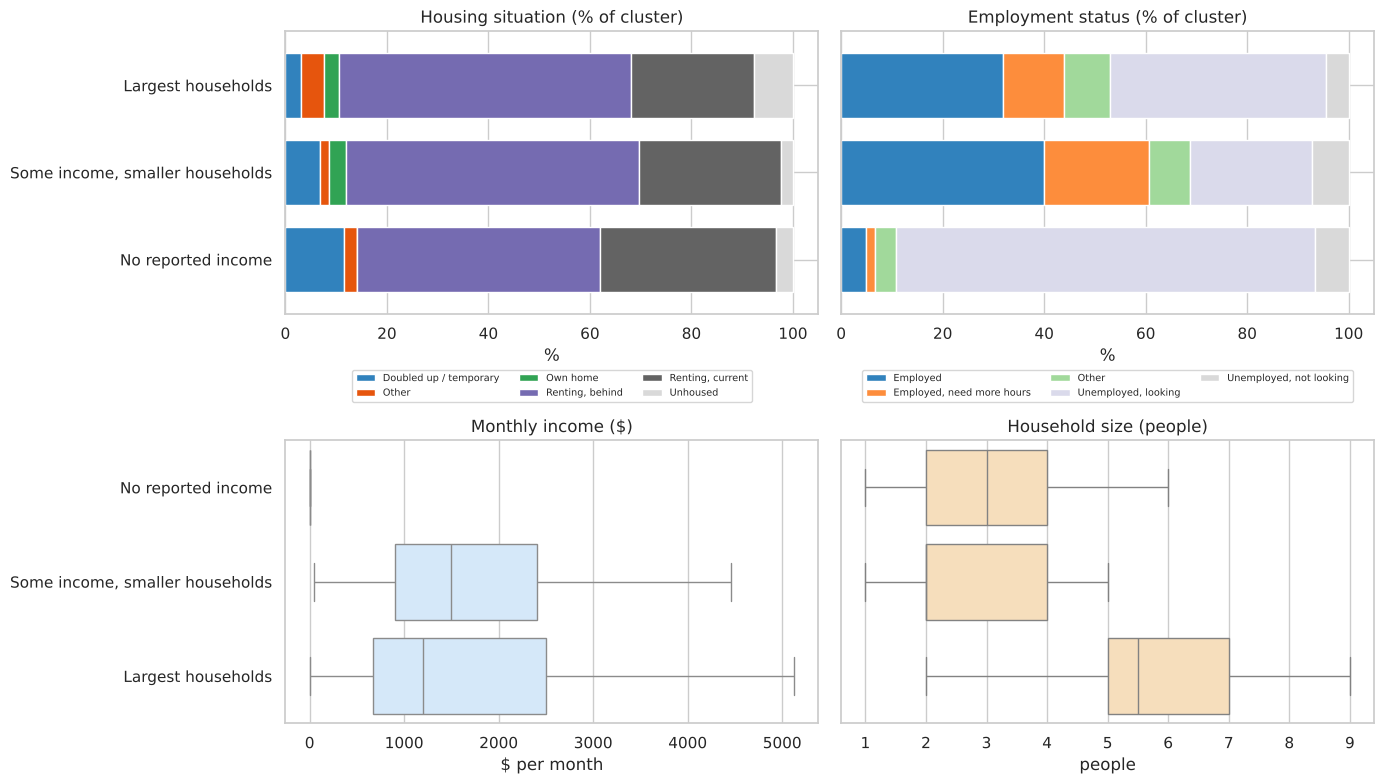

In [20]:
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
(pd.crosstab(analysis['kmeans'], analysis['housing_group'], normalize='index') * 100).plot(kind='barh', stacked=True, ax=ax[0, 0], colormap='tab20c', width=.75)
ax[0, 0].set(title='Housing situation (% of cluster)', xlabel='%', ylabel=''); ax[0, 0].legend(fontsize=7, loc='upper center', bbox_to_anchor=(.5, -.18), ncol=3)
emp_short = analysis['employment_status'].replace({'Employed, but need more hours and/or different work': 'Employed, need more hours',
                                                   'Unemployed but want to find work': 'Unemployed, looking',
                                                   'Unemployed and not looking for work': 'Unemployed, not looking'})
(pd.crosstab(analysis['kmeans'], emp_short, normalize='index') * 100).plot(kind='barh', stacked=True, ax=ax[0, 1], colormap='tab20c', width=.75)
ax[0, 1].set(title='Employment status (% of cluster)', xlabel='%', ylabel=''); ax[0, 1].legend(fontsize=7, loc='upper center', bbox_to_anchor=(.5, -.18), ncol=3)
ax[0, 1].set_yticklabels([])
sns.boxplot(data=analysis, y='kmeans', x='income_monthly', ax=ax[1, 0], color='#cfe8ff', showfliers=False, orient='h')
ax[1, 0].set(title='Monthly income ($)', xlabel='$ per month', ylabel='')
sns.boxplot(data=analysis, y='kmeans', x='household_size_from_members', ax=ax[1, 1], color='#ffe0b3', showfliers=False, orient='h')
ax[1, 1].set(title='Household size (people)', xlabel='people', ylabel=''); ax[1, 1].set_yticklabels([])
plt.tight_layout(); plt.savefig('part2_fig_profiles.png', dpi=150, bbox_inches='tight'); plt.show()

In [21]:
gh = analysis.groupby('hierarchical', observed=True)
display(pd.DataFrame({'people': gh.size(), 'median income ($)': gh['income_monthly'].median(),
                      '% with $0 income': (gh['income_monthly'].apply(lambda s: (s == 0).mean()) * 100).round(0),
                      'mean household size': gh['household_size_from_members'].mean().round(1),
                      '% rent past due (housing group)': (gh['housing_group'].apply(lambda s: (s == 'Renting, behind').mean()) * 100).round(0),
                      '% currently being evicted': (gh['eviction_status'].apply(lambda s: (s == 'Currently being evicted').mean()) * 100).round(0)}))

,people,median income ($),% with $0 income,mean household size,% rent past due (housing group),% currently being evicted
hierarchical,,,,,,
No reported income,113,0.0,100.0,3.0,52.0,21.0
"Some income, smaller households",253,1500.0,0.0,3.1,60.0,28.0
Largest households,29,600.0,41.0,6.9,21.0,21.0


## Policy Questions 1-4
The four policy questions are labelled Q1 to Q4 below, matching the handout and the written report: Q1 = patterns of need, Q2 = overlapping pressures, Q3 = repeat needs and missing information, Q4 = program and policy implications.

### Q1. Different patterns of need

In [22]:
same = (analysis['kmeans'] == analysis['hierarchical']).groupby(analysis['kmeans'], observed=True).agg(['sum', 'size'])
same.columns = ['same_cluster_in_both', 'people']
same['% in matching cluster'] = (same['same_cluster_in_both'] / same['people'] * 100).round(0)
display(same)
print(f'Overall: adjusted Rand index {ari:.2f}; bootstrap ARI is in the table in 2.3')

,same_cluster_in_both,people,% in matching cluster
kmeans,,,
No reported income,112,121,93.0
"Some income, smaller households",208,208,100.0
Largest households,24,66,36.0


Overall: adjusted Rand index 0.70; bootstrap ARI is in the table in 2.3



**Q1 answer.** Yes, but only weakly. The records support three overlapping patterns, not sharply separated groups (silhouette 0.21). Housing pressure is *not* what separates them: in every cluster 48-58% of people are renting with rent past due. What separates them is income/employment and household size.

| Cluster (K-Means) | People | Defining characteristics |
|---|---|---|
| No reported income | 121 (30.6%) | 97% report $0 income; 83% are unemployed and looking for work; 78% list "No income" as a source and 45% SNAP/TANF; household size 3.1 |
| Some income, smaller households | 208 (52.7%) | Median income $1,500 and none at $0; 61% employed (40% employed, 21% employed but needing more hours); 41% full-time income; household size 2.7 |
| Largest households | 66 (16.7%) | Mean household size 5.9 with 4.2 children (1.9 roster members aged 0-5); median income $1,200; SSI/SSDI reported by 26%; 29% have a voucher |

**Stability across methods.** The first two patterns are stable: Ward reproduces 93% of the no-income cluster and all of the middle cluster. The *largest households* group is the least stable (only 36% agreement; the boundary depends on where household size is cut). Bootstrap ARI is 0.86 for k = 3. These are exploratory descriptions of the intake data, not validated categories of need.


### Q2. Overlapping pressures

In [23]:
analysis['past_due_flag'] = analysis['high_arrears_3000']
g = analysis.groupby('kmeans', observed=True)
non_input = pd.DataFrame({
    'people': g.size(),
    'rent form completed (n)': g['rent_form_completed'].apply(lambda s: int((s == 'Yes').sum())),
    'past-due amount recorded (n)': g['past_due_rent'].count(),
    'median past-due rent ($, recorded only)': g['past_due_rent'].median().round(0),
    'past due >= $3,000 (n)': g['high_arrears_3000'].apply(lambda s: int((s == 1).sum())),
    '... as % of recorded': (g['high_arrears_3000'].apply(lambda s: s.mean()) * 100).round(0),
    'utility past due, LG&E/Water (%)': (g['utility_past_due'].apply(lambda s: s.isin(['LG&E', 'Water']).mean()) * 100).round(0),
    'utility "Not recorded" (%)': (g['utility_past_due'].apply(lambda s: (s == 'Not recorded').mean()) * 100).round(0),
    'court date recorded (%)': (g['has_court_date'].apply(lambda s: (s == 'Yes').mean()) * 100).round(0),
    'repairs needed (%)': (g['household_repairs_required'].apply(lambda s: (s == 'Yes').mean()) * 100).round(0),
})
display(non_input)

,people,rent form completed (n),past-due amount recorded (n),"median past-due rent ($, recorded only)","past due >= $3,000 (n)",... as % of recorded,"utility past due, LG&E/Water (%)","utility ""Not recorded"" (%)",court date recorded (%),repairs needed (%)
kmeans,,,,,,,,,,
No reported income,121,39,37,1600.0,7,19.0,58.0,37.0,10.0,16.0
"Some income, smaller households",208,89,86,1885.0,25,29.0,47.0,49.0,18.0,23.0
Largest households,66,31,30,2600.0,14,47.0,62.0,33.0,21.0,21.0


,Income of $0 *,Not employed *,"Renting, rent past due *",Currently being evicted *,Unhoused or doubled up *,Has voucher *,Utility past due (LG&E/Water),Court date recorded,Home needs repairs
kmeans,,,,,,,,,
No reported income,97.0,89.0,48.0,20.0,15.0,30.0,58.0,10.0,16.0
"Some income, smaller households",0.0,31.0,58.0,28.0,9.0,14.0,47.0,18.0,23.0
Largest households,12.0,47.0,58.0,30.0,11.0,29.0,62.0,21.0,21.0


Pressures that go together most (largest positive correlations):


correlation
Not employed *            Has voucher *                     0.21
Renting, rent past due *  Court date recorded               0.36
                          Currently being evicted *         0.42
Income of $0 *            Not employed *                    0.49
Currently being evicted * Court date recorded               0.60

Pressures that rarely go together (most negative correlations):


correlation
Renting, rent past due * Unhoused or doubled up *             -0.39
                         Has voucher *                        -0.29
Unhoused or doubled up * Utility past due (LG&E/Water)        -0.21
Has voucher *            Court date recorded                  -0.13

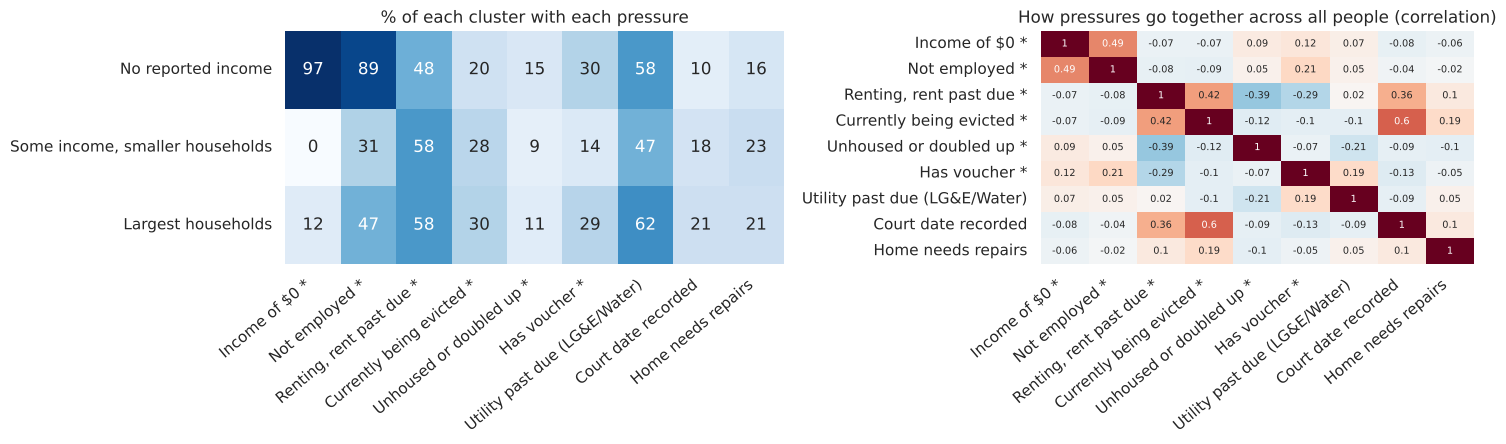

In [24]:
P = pd.DataFrame({
    'Income of $0 *':                       analysis['income_monthly'] == 0,
    'Not employed *':                       analysis['employment_status'].str.startswith('Unemployed'),
    'Renting, rent past due *':             analysis['housing_group'] == 'Renting, behind',
    'Currently being evicted *':            analysis['eviction_status'] == 'Currently being evicted',
    'Unhoused or doubled up *':             analysis['housing_group'].isin(['Unhoused', 'Doubled up / temporary']),
    'Has voucher *':                        analysis['section8_or_voucher'] == 'Yes',
    'Utility past due (LG&E/Water)':        analysis['utility_past_due'].isin(['LG&E', 'Water']),
    'Court date recorded':                  analysis['has_court_date'] == 'Yes',
    'Home needs repairs':                   analysis['household_repairs_required'] == 'Yes',
}).fillna(False).astype(float)
by_cluster = P.groupby(analysis['kmeans'], observed=True).mean().mul(100).round(0)
display(by_cluster)

cm = P.corr()
pairs = cm.where(np.triu(np.ones(cm.shape, dtype=bool), k=1)).stack().dropna().sort_values()
print('Pressures that go together most (largest positive correlations):'); display(pairs.tail(5).round(2).to_frame('correlation'))
print('Pressures that rarely go together (most negative correlations):'); display(pairs.head(4).round(2).to_frame('correlation'))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={'width_ratios': [1.15, 1]})
sns.heatmap(by_cluster, annot=True, fmt='.0f', cmap='Blues', cbar=False, ax=ax[0])
ax[0].set(title='% of each cluster with each pressure', ylabel='', xlabel=''); ax[0].tick_params(axis='x', rotation=40)
for lab in ax[0].get_xticklabels(): lab.set_ha('right')
sns.heatmap(P.corr().round(2), annot=True, cmap='RdBu_r', center=0, vmin=-1, vmax=1, cbar=False, ax=ax[1], annot_kws={'size': 7})
ax[1].set(title='How pressures go together across all people (correlation)')
ax[1].tick_params(axis='x', rotation=40)
for lab in ax[1].get_xticklabels(): lab.set_ha('right')
plt.tight_layout(); plt.savefig('part2_fig_pressures.png', dpi=150, bbox_inches='tight'); plt.show()

In [25]:
analysis['employment_group'] = np.where(analysis['employment_status'].str.startswith('Employed'), 'Employed (any)', 'Not employed / other')
e = analysis.groupby('employment_group')
display(pd.DataFrame({'people': e.size(),
                      '% renting, rent past due': (e['housing_group'].apply(lambda s: (s == 'Renting, behind').mean()) * 100).round(0),
                      '% currently being evicted': (e['eviction_status'].apply(lambda s: (s == 'Currently being evicted').mean()) * 100).round(0),
                      'past-due recorded (n)': e['past_due_rent'].count(),
                      'median past-due ($)': e['past_due_rent'].median().round(0),
                      '% >= $3,000 of recorded': (e['high_arrears_3000'].mean() * 100).round(0)}))

,people,"% renting, rent past due",% currently being evicted,past-due recorded (n),median past-due ($),"% >= $3,000 of recorded"
employment_group,,,,,,
Employed (any),163,60.0,31.0,69,1917.0,36.0
Not employed / other,232,51.0,22.0,84,1948.0,25.0



**Q2 answer.** (Percentages below are within each cluster. Rent-arrears amounts exist only for people who completed the rent form, 37 / 86 / 30 people in the three clusters, so those comparisons are small-sample and suggestive.)

- **Income and employment go together; housing pressure mostly does not follow them.** Income of $0 and not being employed are correlated (0.49), but neither is correlated with being behind on rent (-0.07 and -0.08) or being evicted (-0.07 and -0.09). The no-income cluster has the *lowest* rent pressure of the three: 48% behind on rent, 20% being evicted, median past-due rent $1,600, and 19% (7 of 37) owing $3,000 or more. It is also the cluster where 30% hold a voucher. It is also the cluster most often unhoused or doubled up (15%, against 9% and 11%).
- **Households with some income are not safer.** In the middle cluster 58% are behind on rent, 28% are being evicted, the median past-due rent is $1,885, and 29% (25 of 86) owe $3,000 or more. Across all 395 people, employed households (any employed status, n = 163) have 60% behind on rent and 31% being evicted, versus 51% and 22% for the rest (n = 232). This matches the Part 1 finding that a job did not protect families.
- **The largest households show the biggest arrears among those with a recorded amount.** 58% are behind on rent, 30% are being evicted, the median past-due rent is $2,600, and 47% (14 of 30) owe $3,000 or more. 11% are unhoused or doubled up.
- **Pairs that go together most:** being evicted with a court date (0.60; partly built in, since a court date is only recorded for eviction cases) and rent past due with eviction (0.42). Rent past due is negatively related to being unhoused or doubled up (-0.39) and to having a voucher (-0.29), partly because housing groups are mutually exclusive.
- **Utility past due** is recorded for 58% / 47% / 62% of the three clusters, but 37% / 49% / 33% are "Not recorded," so utility strain cannot be compared reliably.

These are descriptive patterns, not cause and effect: nothing here shows that income, employment or household size *causes* arrears or eviction.


### Q3. Repeat needs and missing information

In [26]:
sub_cols = ['n_care_path_subtickets', 'sub_basic_needs', 'sub_housing_navigation', 'sub_legal', 'sub_other_support', 'sub_rent_assistance', 'sub_utility']
per_person = profiles.groupby('pid')[sub_cols].sum()
analysis['repeat_person'] = analysis['pid_n_profile_tickets'] >= 2
analysis['any_subticket'] = analysis['pid'].map(per_person['n_care_path_subtickets']) > 0
g = analysis.groupby('kmeans', observed=True)
rep = pd.DataFrame({'people': g.size(),
                    'repeat people (n)': g['repeat_person'].sum().astype(int),
                    'repeat (%)': (g['repeat_person'].mean() * 100).round(1),
                    'with 1+ sub-ticket (n)': g['any_subticket'].sum().astype(int),
                    'with 1+ sub-ticket (%)': (g['any_subticket'].mean() * 100).round(0)})
tot = rep[['people', 'repeat people (n)', 'with 1+ sub-ticket (n)']].sum()
display(rep); print('Totals:', tot.to_dict())

kinds = per_person.reindex(analysis['pid'].to_numpy())[sub_cols[1:]].set_axis(analysis.index).groupby(analysis['kmeans'], observed=True).sum()
kinds.columns = [c.replace('sub_', '') for c in kinds.columns]
kinds['total'] = kinds.sum(axis=1)
print('Care-path sub-tickets by type (counts):'); display(kinds)

,people,repeat people (n),repeat (%),with 1+ sub-ticket (n),with 1+ sub-ticket (%)
kmeans,,,,,
No reported income,121,9,7.4,53,44.0
"Some income, smaller households",208,13,6.2,81,39.0
Largest households,66,5,7.6,28,42.0


Totals: {'people': 395, 'repeat people (n)': 27, 'with 1+ sub-ticket (n)': 162}
Care-path sub-tickets by type (counts):


,basic_needs,housing_navigation,legal,other_support,rent_assistance,utility,total
kmeans,,,,,,,
No reported income,14,11,2,9,31,1,68
"Some income, smaller households",12,10,4,2,61,10,99
Largest households,4,1,1,5,21,1,33


In [27]:
parent = profiles[['issue_key', 'pid']].rename(columns={'issue_key': 'parent_issue_key', 'pid': 'parent_pid'})
sp = subs.merge(parent, on='parent_issue_key', how='left')
person_cluster = analysis.set_index('pid')['kmeans']
sp['parent_cluster'] = sp['parent_pid'].map(person_cluster)
print('Sub-tickets with a parent profile in the file:', int(sp['parent_in_file'].eq('Yes').sum()), 'of', len(sp),
      '| PID differs from the parent profile:', int(sp['pid_matches_parent'].eq('No').sum()))
mm = pd.crosstab(sp['parent_cluster'], sp['pid_matches_parent'])
display(mm)
print('Rent-form completion (needed for arrears) by cluster is in the Q2 table; people with no sub-ticket or no repeat intake are not "stable", just not recorded.')

Sub-tickets with a parent profile in the file: 200 of 213 | PID differs from the parent profile: 31


pid_matches_parent,No,Yes
parent_cluster,,
No reported income,10,58
"Some income, smaller households",17,82
Largest households,4,29


Rent-form completion (needed for arrears) by cluster is in the Q2 table; people with no sub-ticket or no repeat intake are not "stable", just not recorded.



**Q3 answer.**
- **Repeat contact is rare and does not differ visibly across clusters.** 27 of 395 people (6.8%) have two or more profile tickets: 9 of 121 (7.4%), 13 of 208 (6.2%), and 5 of 66 (7.6%). With counts this small, we cannot say any cluster returns more often.
- **Care-path sub-tickets are also similar.** 162 people (41%) have at least one linked sub-ticket: 53 (44%), 81 (39%) and 28 (42%). Rent assistance is the main type everywhere (113 of the 200 sub-tickets linked to these people). The middle cluster holds 10 of the 12 utility sub-tickets; basic-needs and housing-navigation sub-tickets are a larger share for the no-income cluster (25 of 68, 37%) than for the middle (22 of 99, 22%) or largest-household cluster (5 of 33, 15%).
- **PID is unreliable for repeat counts.** 31 of the 200 sub-tickets with a parent in the file carry a different PID from their parent profile (10, 17 and 4 across the three clusters; 12-17% in each). The same family can appear under two PIDs, so repeat counts are approximate and probably too low.

**What we would still need** to tell immediate crisis from recurring instability, or to judge whether help worked: a reliable person/household ID; dates and amounts of assistance received; housing status *after* the intake (the data only show intake, and case status is a workflow field, not an outcome); the reason an eviction status is recorded as Unknown; and the rent form completed for all renters (it is missing for most profiles, so arrears are unknown for many).


### Q4. SLCM program and policy implications

In [28]:
evidence = pd.DataFrame({
    'people': summary['people'],
    '% renting, rent past due': by_cluster['Renting, rent past due *'],
    '% being evicted': by_cluster['Currently being evicted *'],
    '% unhoused or doubled up': by_cluster['Unhoused or doubled up *'],
    '% with voucher': by_cluster['Has voucher *'],
    'median past-due ($, recorded)': non_input['median past-due rent ($, recorded only)'],
    'past-due amount recorded (n)': non_input['past-due amount recorded (n)'],
})
display(evidence)

,people,"% renting, rent past due",% being evicted,% unhoused or doubled up,% with voucher,"median past-due ($, recorded)",past-due amount recorded (n)
kmeans,,,,,,,
No reported income,121,48.0,20.0,15.0,30.0,1600.0,37
"Some income, smaller households",208,58.0,28.0,9.0,14.0,1885.0,86
Largest households,66,58.0,30.0,11.0,29.0,2600.0,30



**Q4 answer.** Two realistic ways SLCM could investigate or tailor services:

**1. Do not screen by income or employment alone; check rent arrears and eviction status for everyone, including employed households.**
*Evidence:* the cluster with some income and mostly employed members is the largest (52.7% of people), with 58% behind on rent and 28% being evicted, and employed households overall are at least as likely to be behind on rent (60% versus 51%) and being evicted (31% versus 22%) as those not employed. Rent assistance is already the largest sub-ticket type in this cluster (61 of 99). SLCM could test whether earlier rent-assistance outreach, combined with a check on work hours and wages, helps employed households with arrears.
*Limitation:* arrears amounts are recorded for only 86 of the 208 people in this cluster, 14% of eviction statuses in this cluster are Unknown, and employment shows association, not cause.

**2. Look at whether large households have enough housing support.**
*Evidence:* the 66 largest households (mean 5.9 people, 4.2 children, 1.9 members aged 0-5) have the highest recorded arrears (median $2,600; 14 of 30 owe $3,000 or more), 11% are unhoused or doubled up, and only 1 of their 33 linked sub-tickets is housing navigation (versus 11 of 68 for the no-income cluster). SLCM could check whether larger rental units or housing-navigation help are hard for these families to find.
*Limitation:* this is the least stable cluster (only 36% agreement between K-Means and Ward), the arrears figure rests on 30 people, and the sub-ticket gap is based on very small counts.

**Why clusters must not decide who gets help.** The silhouette score is only 0.21 and the methods disagree about one cluster, so many families sit between groups. The clusters rely on fields with Unknown and "Not recorded" answers, they describe the intake form and not a family's full situation, and they were built without any information about outcomes. A family's cluster tells staff nothing about eligibility, and using it to ration help could miss families who are in crisis but look like another group. Assistance decisions should stay with staff assessment of the individual household.


## What Did You Learn?


**(a) Strongest discovery.** Income and employment do not sort SLCM families by housing trouble. The households with no reported income, the households with some income, and the largest households all show a similar level of rent pressure (48-58% behind on rent), and employed households are at least as likely to be behind and being evicted (60% and 31%) as those who are not (51% and 22%). What does differ between groups is household size and how income is made up.

**(b) Unexpected result or method disagreement.** We expected the no-income households to be in the worst housing shape, but they had the *lowest* eviction share (20%) and smaller arrears among those with a recorded amount, and 30% of them have a voucher. We also found that the two methods disagree about the largest households (only 36% agreement) and that a four-cluster solution is not repeatable, so we did not use it.

**(c) What the data cannot answer.** Whether any group is more at risk later, whether assistance helped, why a status is Unknown, and rent arrears for the majority of families who never completed the rent form. The clusters are descriptions of intake answers, not validated risk categories.

**(d) Suggestion for data collection.** Have staff complete the rent form for every renter (and record "none" explicitly for utilities), add a reason code when eviction status is Unknown, record follow-up housing status after assistance, and use a more reliable person/household ID so repeat contact can be counted accurately.
